# Predictive Maintenance — Complete Interim Capstone Analysis

**Submitted by: Amandeep Kaur**

**Source:** engine_data.csv, 19,535 rows. This notebook shows executed EDA and a separately executed six-algorithm training script. **Class 1 is treated as the positive numerical label; its business meaning is not verified.**

## 1. Data registration — read CSV and verify schema
We first validate the seven expected columns, target values, data types, missing cells, and duplicates. This prevents a misleading model being trained on an incorrect or incomplete file.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from joblib import dump
root=Path.cwd()
if not (root/'data'/'engine_data.csv').exists(): root=root.parent
assert (root/'data'/'engine_data.csv').exists(), 'Run from project root or notebooks/ with data/ present'
df=pd.read_csv(root/'data'/'engine_data.csv')
expected=['Engine rpm','Lub oil pressure','Fuel pressure','Coolant pressure','lub oil temp','Coolant temp','Engine Condition']
assert list(df.columns)==expected, f'Unexpected schema: {df.columns.tolist()}'
assert set(df['Engine Condition'].dropna().unique()).issubset({0,1})
print('Dataset shape:',df.shape)
print('Data types:'); print(df.dtypes.to_string())
print('Missing values per column:'); print(df.isna().sum().to_string())
print('Exact duplicate rows:',df.duplicated().sum())
print('Target counts:'); print(df['Engine Condition'].value_counts().sort_index().to_string())

Dataset shape: (19535, 7)
Data types:
Engine rpm            int64
Lub oil pressure    float64
Fuel pressure       float64
Coolant pressure    float64
lub oil temp        float64
Coolant temp        float64
Engine Condition      int64
Missing values per column:
Engine rpm          0
Lub oil pressure    0
Fuel pressure       0
Coolant pressure    0
lub oil temp        0
Coolant temp        0
Engine Condition    0
Exact duplicate rows: 0
Target counts:
Engine Condition
0     7218
1    12317


## 2. EDA — data overview
The descriptive table identifies each sensor’s range, central tendency and dispersion. Extreme readings are **flagged for domain review**, not automatically deleted, because rare sensor conditions may be informative.

In [2]:
display(df.describe().T.round(2))
print('Class percentages:'); print((df['Engine Condition'].value_counts(normalize=True).sort_index()*100).round(2).to_string())

,count,mean,std,min,25%,50%,75%,max
Engine rpm,19535.0,791.24,267.61,61.00,593.00,746.00,934.00,2239.00
Lub oil pressure,19535.0,3.30,1.02,0.00,2.52,3.16,4.06,7.27
Fuel pressure,19535.0,6.66,2.76,0.00,4.92,6.20,7.74,21.14
Coolant pressure,19535.0,2.34,1.04,0.00,1.60,2.17,2.85,7.48
lub oil temp,19535.0,77.64,3.11,71.32,75.73,76.82,78.07,89.58
Coolant temp,19535.0,78.43,6.21,61.67,73.90,78.35,82.92,195.53
Engine Condition,19535.0,0.63,0.48,0.00,0.00,1.00,1.00,1.00


Class percentages:
Engine Condition
0    36.95
1    63.05


### 2.1 Univariate analysis — histograms
A histogram shows where each sensor usually operates and whether its distribution has skew, tails or unusual clusters. These findings guide anomaly review and model selection.

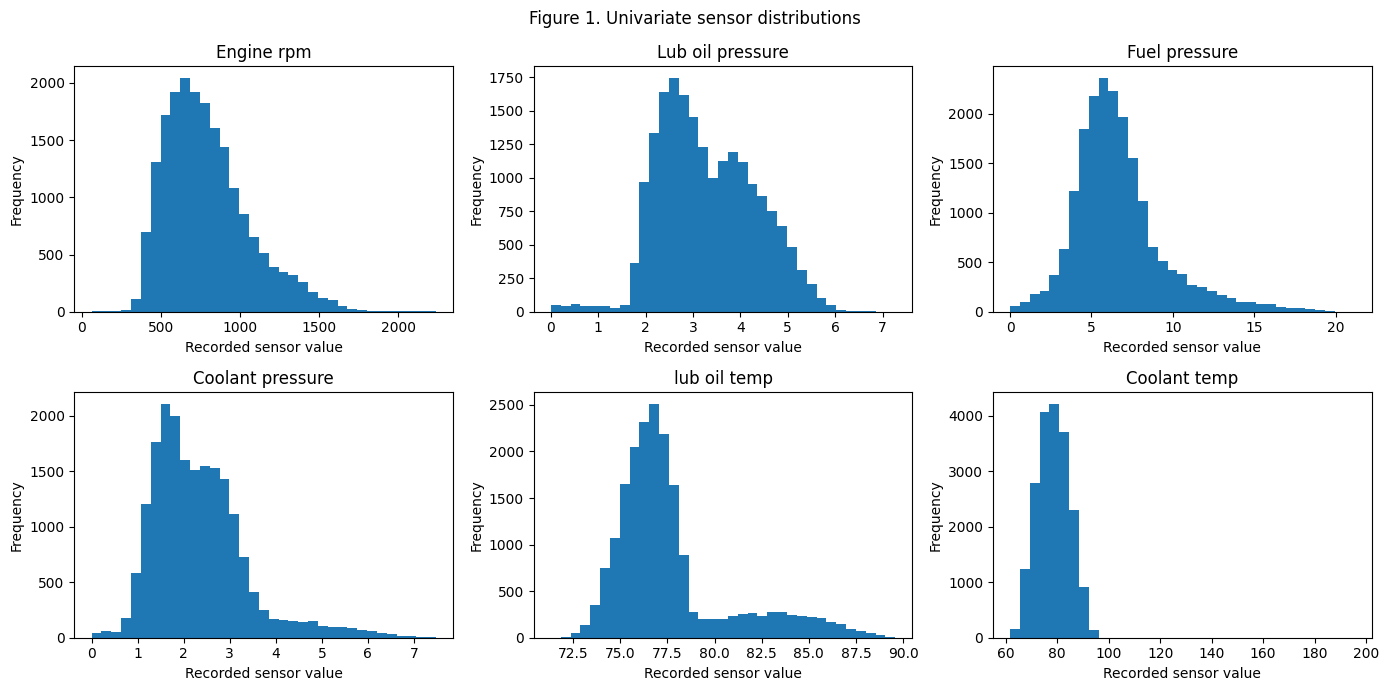

In [3]:
features=expected[:-1]
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,c in zip(axes.flat,features): ax.hist(df[c],bins=35); ax.set_title(c);ax.set_xlabel('Recorded sensor value');ax.set_ylabel('Frequency')
fig.suptitle('Figure 1. Univariate sensor distributions');plt.tight_layout();plt.show()

### 2.2 Outlier inspection — boxplots
The boxplot displays the median, quartiles and points beyond conventional whiskers. Such points are not necessarily data errors; operating state, engine type and sensor units must be checked.

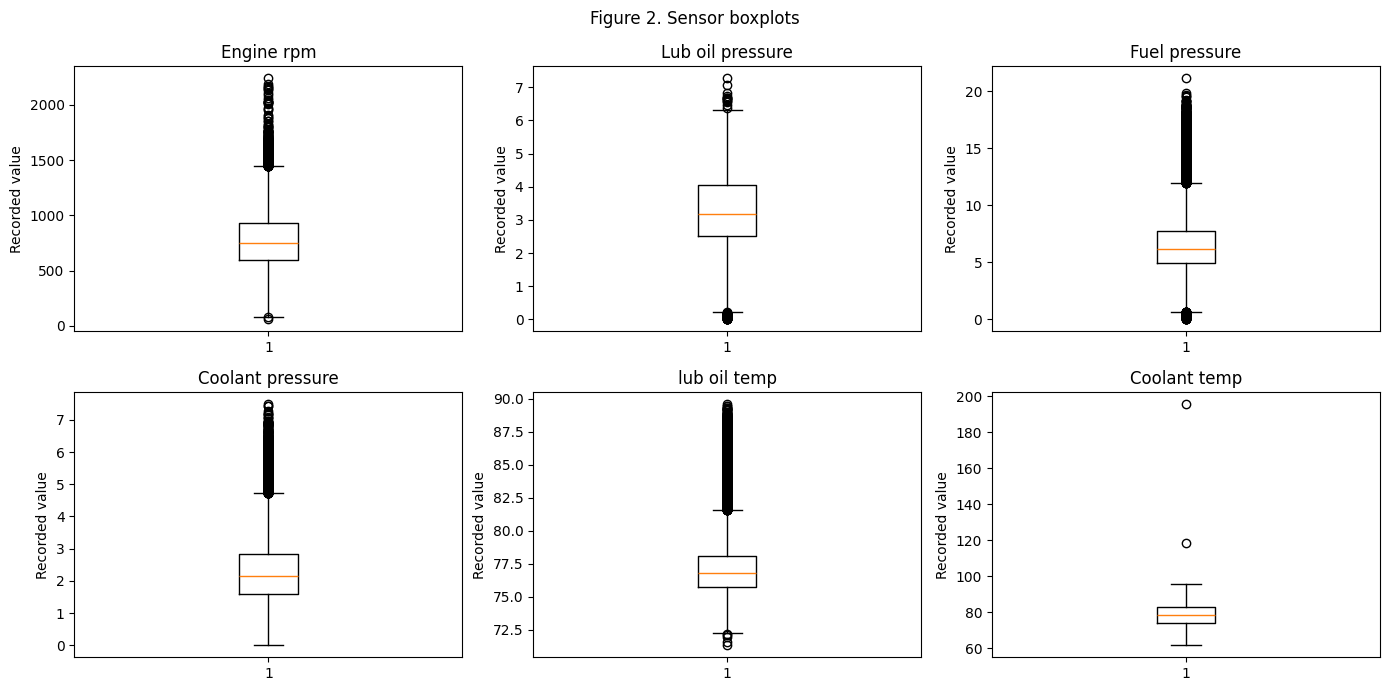

Engine rpm: 464 IQR-flagged readings; min=61.00, max=2239.00
Lub oil pressure: 66 IQR-flagged readings; min=0.00, max=7.27
Fuel pressure: 1,135 IQR-flagged readings; min=0.00, max=21.14
Coolant pressure: 785 IQR-flagged readings; min=0.00, max=7.48
lub oil temp: 2,617 IQR-flagged readings; min=71.32, max=89.58
Coolant temp: 2 IQR-flagged readings; min=61.67, max=195.53


In [4]:
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,c in zip(axes.flat,features): ax.boxplot(df[c].dropna());ax.set_title(c);ax.set_ylabel('Recorded value')
fig.suptitle('Figure 2. Sensor boxplots');plt.tight_layout();plt.show()
for c in features:
 q1,q3=df[c].quantile([.25,.75]);lo=q1-1.5*(q3-q1);hi=q3+1.5*(q3-q1)
 print(f'{c}: {((df[c]<lo)|(df[c]>hi)).sum():,} IQR-flagged readings; min={df[c].min():.2f}, max={df[c].max():.2f}')

### 2.3 Bivariate analysis — sensors versus target
Class-conditional means provide a simple comparison. Distributions may still overlap even if means differ, so these are descriptive associations, not causal evidence.

Engine rpm        Lub oil pressure  ... lub oil temp Coolant temp       
                       mean median             mean  ...       median         mean median
Engine Condition                                     ...                                 
0                     885.0  843.0             3.22  ...        77.09        78.80  78.77
1                     736.3  690.0             3.35  ...        76.66        78.21  78.10

[2 rows x 12 columns]

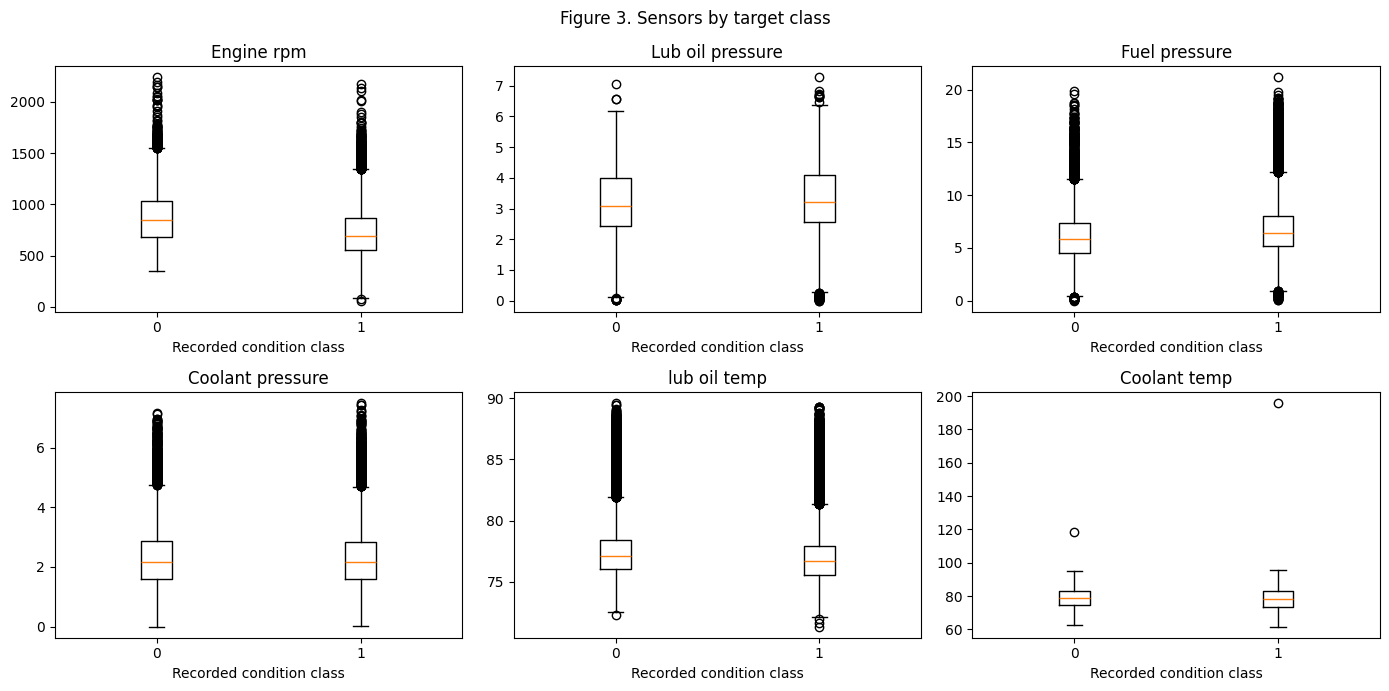

In [5]:
display(df.groupby('Engine Condition')[features].agg(['mean','median']).round(2))
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,c in zip(axes.flat,features):
 ax.boxplot([df.loc[df['Engine Condition']==k,c].dropna() for k in [0,1]],tick_labels=['0','1']);ax.set_title(c);ax.set_xlabel('Recorded condition class')
fig.suptitle('Figure 3. Sensors by target class');plt.tight_layout();plt.show()

### 2.4 Multivariate analysis — Pearson correlation
Correlation measures **linear association**, not cause and effect. It can help identify related predictors, but tree ensembles can also learn nonlinear interactions.

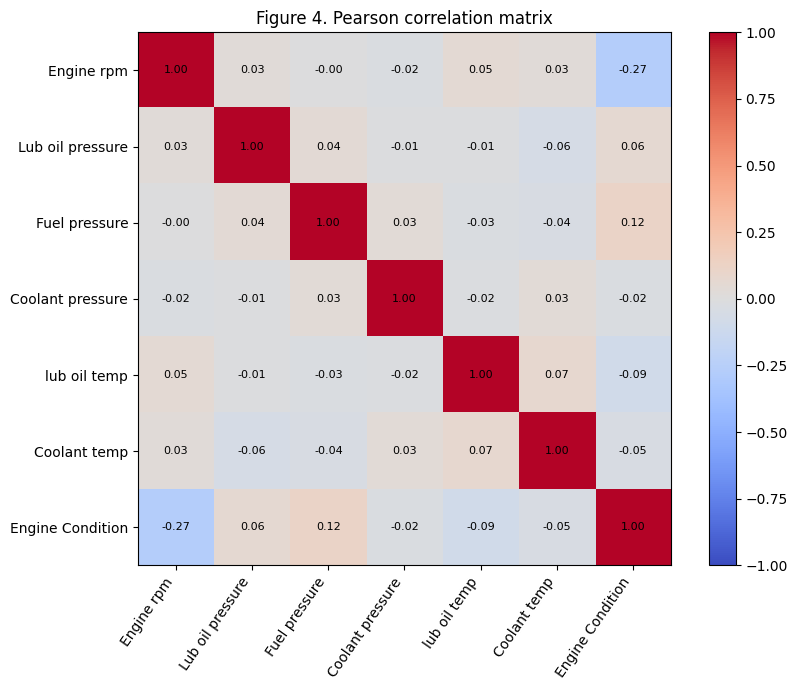

Correlations with recorded class:
Engine rpm         -0.268
lub oil temp       -0.094
Coolant temp       -0.046
Coolant pressure   -0.024
Lub oil pressure    0.061
Fuel pressure       0.116
Engine Condition    1.000


In [6]:
corr=df.corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(9,7));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr.columns)),corr.columns,rotation=55,ha='right');ax.set_yticks(range(len(corr.index)),corr.index)
for i in range(len(corr)):
 for j in range(len(corr)):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=ax);ax.set_title('Figure 4. Pearson correlation matrix');plt.tight_layout();plt.show()
print('Correlations with recorded class:');print(corr['Engine Condition'].sort_values().round(3).to_string())

## 3. Data preparation — explain and save the split
We use an **80/20 stratified split** to keep the numerical class proportions similar in training and test data. `random_state=42` makes the split repeatable. Missing values, if any, are imputed **inside** the fitted model pipeline so that validation folds and test records cannot influence the training imputation values. We retain unusual sensor readings until they are independently verified as invalid.

In [7]:
X=df[features].copy();y=df['Engine Condition'].copy()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=42)
art=root/'artifacts';art.mkdir(exist_ok=True)
for name,value in [('X_train',X_train),('X_test',X_test),('y_train',y_train.to_frame()),('y_test',y_test.to_frame())]:value.to_csv(art/f'{name}.csv',index=False)
print('Train:',X_train.shape,'Test:',X_test.shape)
print('Train class %:',(y_train.value_counts(normalize=True)*100).round(2).to_dict())
print('Test class %:',(y_test.value_counts(normalize=True)*100).round(2).to_dict())

Train: (15628, 6) Test: (3907, 6)
Train class %: {1: 63.05, 0: 36.95}
Test class %: {1: 63.04, 0: 36.96}


## 4. Model experimentation — all six algorithms
The following training script was executed locally against the saved 80/20 split. It runs Decision Tree, Bagging, Random Forest, AdaBoost, Gradient Boosting and XGBoost. Each receives four hyperparameter combinations evaluated with stratified three-fold cross-validation. Model selection uses only training CV F1; the held-out test set is evaluated once after selection. The exact code is displayed below and stored as `scripts/train_model.py`.

In [12]:
from pathlib import Path
import json, pandas as pd
from joblib import dump
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier,RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
from xgboost import XGBClassifier
r=Path(__file__).resolve().parents[1];a=r/'artifacts';m=r/'models';m.mkdir(exist_ok=True)
X=pd.read_csv(a/'X_train.csv');Xt=pd.read_csv(a/'X_test.csv');y=pd.read_csv(a/'y_train.csv').iloc[:,0];yt=pd.read_csv(a/'y_test.csv').iloc[:,0]
models={
 'Decision Tree':(DecisionTreeClassifier(random_state=42),{'model__max_depth':[4,8],'model__min_samples_leaf':[5,20]}),
 'Bagging':(BaggingClassifier(random_state=42,n_jobs=1),{'model__n_estimators':[15,25],'model__max_samples':[0.8,1.0]}),
 'Random Forest':(RandomForestClassifier(random_state=42,n_jobs=1),{'model__n_estimators':[20,35],'model__max_depth':[8,12]}),
 'AdaBoost':(AdaBoostClassifier(random_state=42),{'model__n_estimators':[20,35],'model__learning_rate':[0.05,0.2]}),
 'Gradient Boosting':(GradientBoostingClassifier(random_state=42),{'model__n_estimators':[20,35],'model__learning_rate':[0.05,0.1]}),
 'XGBoost':(XGBClassifier(random_state=42,n_jobs=1,eval_metric='logloss',tree_method='hist'),{'model__n_estimators':[20,35],'model__max_depth':[3,5]})}
rows=[];best=None;bestname=None;bestscore=-1
for name,(est,grid) in models.items():
 s=GridSearchCV(Pipeline([('imputer',SimpleImputer(strategy='median')),('model',est)]),grid,cv=StratifiedKFold(3,shuffle=True,random_state=42),scoring='f1',n_jobs=1);s.fit(X,y)
 rows.append({'model':name,'cv_f1_mean':s.best_score_,'best_parameters':json.dumps(s.best_params_)})
 if s.best_score_>bestscore:best=s.best_estimator_;bestname=name;bestscore=s.best_score_;params=s.best_params_
pd.DataFrame(rows).to_csv(a/'workflow_experiments.csv',index=False)
pred=best.predict(Xt);result={'selected_model':bestname,'best_parameters':params,'cv_f1':bestscore,'accuracy':accuracy_score(yt,pred),'precision':precision_score(yt,pred),'recall':recall_score(yt,pred),'f1':f1_score(yt,pred),'confusion_matrix':confusion_matrix(yt,pred).tolist()}
dump(best,m/'best_model.joblib');(a/'pipeline_evaluation.json').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2))


{
  "selected_model": "Gradient Boosting",
  "best_parameters": {
    "model__learning_rate": 0.05,
    "model__n_estimators": 20
  },
  "cv_f1": 0.7772805555515054,
  "accuracy": 0.6501151778858459,
  "precision": 0.6494002181025081,
  "recall": 0.9671132764920828,
  "f1": 0.7770347414777361,
  "confusion_matrix": [
    [
      158,
      1286
    ],
    [
      81,
      2382
    ]
  ]
}


### Experiment log and model comparison
The following is the actual output of the six-model training script. The experiment CSV is created by the same script, and the selected model is persisted to `models/best_model.joblib`. The notebook does not claim that GitHub Actions ran remotely.

In [13]:
comparison = pd.read_csv('artifacts/workflow_experiments.csv')
display(comparison)
print('Saved evaluation:')
print(Path('artifacts/pipeline_evaluation.json').read_text())

            model  cv_f1_mean                                           best_parameters
    Decision Tree    0.754408    {"model__max_depth": 4, "model__min_samples_leaf": 20}
          Bagging    0.735028    {"model__max_samples": 0.8, "model__n_estimators": 25}
    Random Forest    0.763854        {"model__max_depth": 8, "model__n_estimators": 35}
         AdaBoost    0.775752  {"model__learning_rate": 0.2, "model__n_estimators": 35}
Gradient Boosting    0.777281 {"model__learning_rate": 0.05, "model__n_estimators": 20}
          XGBoost    0.762688        {"model__max_depth": 3, "model__n_estimators": 20}

Saved evaluation:
{
  "selected_model": "Gradient Boosting",
  "best_parameters": {
    "model__learning_rate": 0.05,
    "model__n_estimators": 20
  },
  "cv_f1": 0.7772805555515054,
  "accuracy": 0.6501151778858459,
  "precision": 0.6494002181025081,
  "recall": 0.9671132764920828,
  "f1": 0.7770347414777361,
  "confusion_matrix": [
    [
      158,
      1286
    ],
    [
      81,
      2382
    ]
  ]
}


## 5. Held-out evaluation and interpretation
**Positive class:** numerical class 1. The confusion matrix is ordered as `[[TN, FP], [FN, TP]]`. Accuracy = (TP+TN)/N; precision = TP/(TP+FP); recall = TP/(TP+FN); F1 = 2TP/(2TP+FP+FN). These scores measure agreement with the dataset labels, not verified failure forecasts.

Accuracy: 0.6501151778858459
Precision: 0.6494002181025081
Recall: 0.9671132764920828
F1: 0.7770347414777361


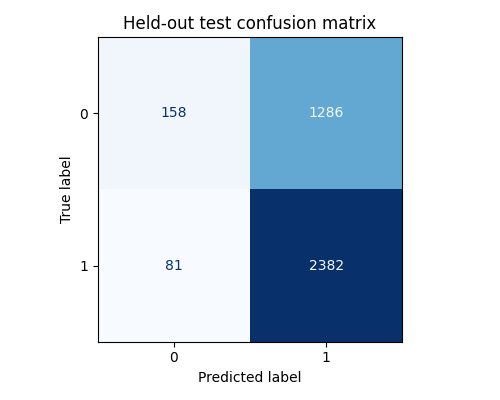

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = [[158, 1286], [81, 2382]]
tn,fp=cm[0]; fn,tp=cm[1]
print('Accuracy:',(tp+tn)/(tp+tn+fp+fn))
print('Precision:',tp/(tp+fp))
print('Recall:',tp/(tp+fn))
print('F1:',2*tp/(2*tp+fp+fn))
ConfusionMatrixDisplay(confusion_matrix=np.array(cm),display_labels=[0,1]).plot(cmap='Blues')
plt.title('Held-out test confusion matrix');plt.show()

## 6. Actionable business recommendations
1. Verify the mapping of 0 and 1 to normal versus maintenance required before issuing alerts.
2. Investigate unusually high coolant temperatures and zero-pressure readings by engine type and sensor state.
3. Set alert thresholds using false-alarm and missed-maintenance costs, not accuracy alone.
4. Validate prospectively with engine IDs, timestamps and actual maintenance outcomes.
5. Monitor sensor drift and recalibrate after field validation.

**Workflow:** `.github/workflows/ml_pipeline.yml` specifies upload of the split files from the prepare job and download in the train job. Local validation, preparation and training scripts were run successfully; a hosted GitHub Actions run has not been performed.